# Exercise Sheet 6 (programming part, unsolved)
*Machine Learning for Data Science, Winter Semester 2026/27 — Prof. Dr.-Ing. Gerhard Wunder, Freie Universität Berlin*

1. Maxim Zotov
1. Furkan Dursun
1. Lewin Ahlgrimm


In this exercise, we consider canonical correlation analysis (CCA) on two simple problems, one in low dimensions and one in high dimensions. The goal is to implement the original CCA procedure, and the CCA variant for high-dimensional data, in order to handle both cases.

We first import the relevant libraries.

In [1]:
import numpy
import scipy
import scipy.linalg
import matplotlib
%matplotlib inline
from matplotlib import pyplot as plt

The first dataset consists of two trajectories in two dimensions. The first data points are shown in dark blue, and the last ones are shown in yellow. The (self-contained) helper functions generating and plotting the data are given below.

In [2]:
def getdata(N=100):
    """Two 2D trajectories (modalities X and Y) that share one latent signal."""
    rng = numpy.random.RandomState(0)
    t = numpy.linspace(0,1,N)
    s = numpy.sin(2*numpy.pi*1.5*t)                # shared latent signal
    X = numpy.stack([0.6*s + 0.15*rng.randn(N),
                     2.0*numpy.sin(2*numpy.pi*4.3*t+1.0) + 0.15*rng.randn(N)])
    Y = numpy.stack([1.8*numpy.cos(2*numpy.pi*3.1*t) + 0.15*rng.randn(N),
                     0.6*s + 0.15*rng.randn(N)])
    return X+numpy.array([[1.0],[0.5]]), Y+numpy.array([[-0.5],[1.0]])   # (not centered)

def plotdata(X,Y):
    fig,(p1,p2) = plt.subplots(1,2,figsize=(8,4))
    for p,Z,name in ((p1,X,'X'),(p2,Y,'Y')):
        p.scatter(*Z,c=numpy.arange(Z.shape[1]),s=15,cmap='viridis')
        p.set_title(f'Modality {name}'); p.set_xlim(-3.5,3.5); p.set_ylim(-3.5,3.5); p.set_aspect('equal')
    return p1,p2

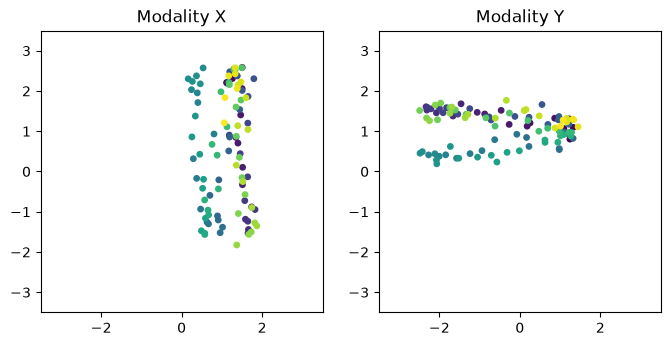

In [3]:
X,Y   = getdata()
p1,p2 = plotdata(X,Y)
plt.show()

For these two trajectories, that can be understood as two different modalities of the same data, we would like to determine under which projections they appear maximally correlated.

## Exercise 3: Implementing CCA (25 P)

As stated in the lecture, the CCA problem in its original form consists of maximizing the cross-correlation objective:

$$J(w_x,w_y) = w_x^\top C_{xy} w_y$$

subject to autocorrelation constraints $w_x^\top C_{xx} w_x = 1$ and $w_y^\top C_{yy} w_y = 1$. Using the method of Lagrange multipliers, this optimization problem can be reduced to finding the first eigenvector of the generalized eigenvalue problem:

$$\begin{bmatrix}0 & C_{xy}\\C_{yx} & 0\end{bmatrix}\begin{bmatrix}w_x\\w_y\end{bmatrix} = \lambda\begin{bmatrix}C_{xx} & 0\\0 & C_{yy}\end{bmatrix}\begin{bmatrix}w_x\\w_y\end{bmatrix}$$

Your first task is to write a function that solves this generalized eigenvalue problem. The function receives two matrices `X` and `Y` of size $d_1 \times N$ and $d_2 \times N$ respectively. It should return two vectors of size $d_1$ and $d_2$ corresponding to the projections associated to the modalities $X$ and $Y$. *(Hint: the data matrices `X` and `Y` have not been centered yet. You can use `scipy.linalg.eigh(S,D)` to solve the generalized eigenvalue problem.)*

In [4]:
def CCA(X,Y):
    X_c = X - X.mean(axis=1)[:, numpy.newaxis]
    Y_c = Y - Y.mean(axis=1)[:, numpy.newaxis]
    d1 = X_c.shape[0]
    d2 = Y_c.shape[0]
    N = X_c.shape[1]
    C_xy = X_c@Y_c.T / N
    C_yx = C_xy.T
    C_xx = X_c@X_c.T / N
    C_yy = Y_c@Y_c.T / N
    # a @ vi = λ * b @ vi
    
    S = numpy.block([
        [numpy.zeros((d1, d1)), C_xy],
        [C_yx, numpy.zeros((d2, d2))]
    ])
    D = numpy.block([
        [C_xx, numpy.zeros((d1, d2))],
        [numpy.zeros((d2, d1)), C_yy]
    ])
    w, v = scipy.linalg.eigh(S, D)
    # because we need maximum, we use
    lambda_max = numpy.argmax(w)
    ev_max = v[:, lambda_max]
    print("w=", w, "v=", v)
    print("lambda_max=", lambda_max, "ev_max = ", ev_max)
    wx = ev_max[:d1]
    wy = ev_max[d1:]
    return wx, wy

The function can now be called with our dataset. The learned projection vectors $w_x$ and $w_y$ are plotted as red arrows.

w= [-0.88858063 -0.19019372  0.19019372  0.88858063] v= [[ 1.53375601  0.03963108 -0.03963108 -1.53375601]
 [-0.00488234  0.4882752  -0.4882752   0.00488234]
 [ 0.00612287 -0.55015918 -0.55015918  0.00612287]
 [-1.68904581 -0.11949787 -0.11949787 -1.68904581]]
lambda_max= 3 ev_max =  [-1.53375601  0.00488234  0.00612287 -1.68904581]
[-1.53375601  0.00488234] [ 0.00612287 -1.68904581]


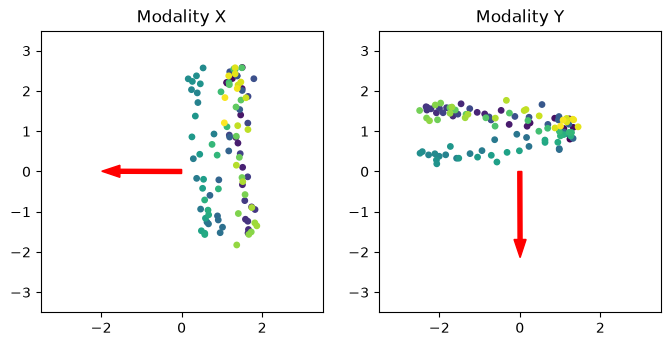

In [5]:
wx,wy = CCA(X,Y)
print(wx, wy)
p1,p2 = plotdata(X,Y)
p1.arrow(0,0,1*wx[0],1*wx[1],color='red',width=0.1)
p2.arrow(0,0,1*wy[0],1*wy[1],color='red',width=0.1)
plt.show()

In each modality, the arrow points in a specific direction (note that the optimal CCA directions are defined up to a sign flip of both $w_x$ and $w_y$). Furthermore, we can verify CCA has learned a meaningful solution by projecting the data on it.

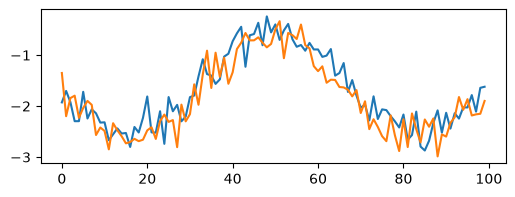

Correlation of projections: 0.889


In [6]:
plt.figure(figsize=(6,2))
plt.plot(wx.dot(X))
plt.plot(wy.dot(Y))
plt.show()

print(f'Correlation of projections: {numpy.corrcoef(wx.dot(X),wy.dot(Y))[0,1]:.3f}')

Clearly, the data is correlated in the projected space.

## Exercise 4: Implementing CCA for High Dimensions (25 P)

In the second part of the exercise, we consider the case where the data is high dimensional (with $d \gg N$). Such high-dimensionality occurs for example, when input data are images. We consider the scenario where sources emit spatially, and two (noisy) receivers measure the spatial field at different locations. We would like to identify the signal that is common to the two measured locations, e.g. a given source emitting at a given frequency. We first load the data and show one example.

In [7]:
L = 20   # images are L x L

def getHDdata(N=100,noise=0.8):
    """N pairs of noisy L x L fields. One point source (common signal) appears in
    both modalities at different locations; each modality also has distractor sources."""
    rng = numpy.random.RandomState(1)
    t = numpy.arange(N)
    gx,gy = numpy.meshgrid(numpy.arange(L),numpy.arange(L))
    blob = lambda cx,cy,w=1.5: numpy.exp(-((gx-cx)**2+(gy-cy)**2)/(2*w**2)).flatten()
    common = numpy.sin(2*numpy.pi*t/9.0)
    def make(c,others):
        F = numpy.outer(blob(*c),common)
        for (p,f,ph) in others:
            F = F + numpy.outer(blob(*p),numpy.sin(2*numpy.pi*t/f+ph))
        return F + noise*rng.randn(L*L,N)
    X = make((5,6),[((14,13),5.3,0.7),((4,15),13.0,2.0)])
    Y = make((14,5),[((6,13),7.1,1.3),((15,16),4.1,0.2)])
    return X,Y

def plotHDdata(x,y):
    fig,(p1,p2) = plt.subplots(1,2,figsize=(6,3))
    for p,z in ((p1,x),(p2,y)):
        p.imshow(z.reshape(L,L),cmap='RdBu_r',vmin=-abs(z).max(),vmax=abs(z).max()); p.axis('off')
    return p1,p2

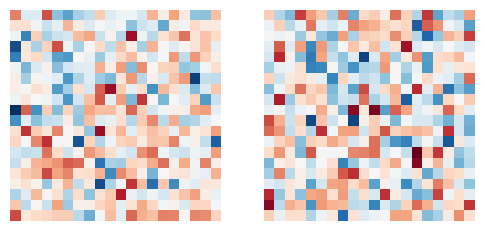

In [8]:
X,Y = getHDdata()

plotHDdata(X[:,0],Y[:,0])
plt.show()

Several sources can be perceived, however, there is a significant level of noise. Here again, we will use CCA to find subspaces where the two modalities are maximally correlated. In this example, because there are many more dimensions than there are data points, it is more advantageous to solve the alternate formulation of CCA in terms of the weightings $\alpha_x$ and $\alpha_y$ (with $w_x = X\alpha_x$, $w_y = Y\alpha_y$). Your task is to implement the latter CCA solver. Like the original CCA solver, it receives two data matrices of size $d_1 \times N$ and $d_2 \times N$ as input, and should return the associated CCA directions (two vectors of respective sizes $d_1$ and $d_2$).

*(Hint: with centered data, $Q_{xy}=\frac1N X^\top X Y^\top Y$, $Q_{xx}=\frac1N X^\top X X^\top X$, $Q_{yy}=\frac1N Y^\top Y Y^\top Y$. These are $N \times N$ and may be singular, so add a small ridge, e.g. $0.01\,X^\top X + 0.01\,I$, to the diagonal blocks of the right-hand matrix.)*

In [9]:
def CCA_HD(X,Y):
    X_c = X - X.mean(axis=1)[:, numpy.newaxis]
    Y_c = Y - Y.mean(axis=1)[:, numpy.newaxis]
    d1 = X_c.shape[0]
    d2 = Y_c.shape[0]
    N = X_c.shape[1]
    Q_xy = 1 / N * X_c.T@X_c@Y_c.T@Y_c
    Q_xx = 1 / N * X_c.T@X_c@X_c.T@X_c
    Q_yy = 1 / N * Y_c.T@Y_c@Y_c.T@Y_c
    Q_yx = Q_xy.T    
    S = numpy.block([
        [numpy.zeros((N, N)), Q_xy],
        [Q_yx, numpy.zeros((N, N))]
    ])
    D = numpy.block([
        [0.01 * X_c.T@X_c + 0.01 * numpy.identity(N), numpy.zeros((N, N))],
        [numpy.zeros((N, N)), 0.01 * Y_c.T@Y_c + 0.01 * numpy.identity(N)]
    ])
    w, v = scipy.linalg.eigh(S, D)
    # because we need maximum, we use
    lambda_max = numpy.argmax(w)
    ev_max = v[:, lambda_max]
    ##print("w=", w, "v=", v)
    ##print("lambda_max=", lambda_max, "ev_max = ", ev_max)
    alpha_x = ev_max[:N] 
    alpha_y = ev_max[N:]
    wx = X_c@alpha_x
    wy = Y_c@alpha_y
    return wx, wy

We now call the function we have implemented with a training sequence of 100 pairs of images. Because the returned solution is of same dimensions as the inputs, it can be rendered in a similar fashion.

(400,) (400,)


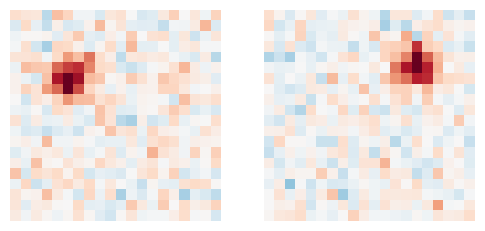

In [10]:
wx,wy = CCA_HD(X,Y)
print(wx.shape, wy.shape)
plotHDdata(wx,wy)
plt.show()

Here, we can clearly see a common factor that has been extracted between the two fields, specifically a point source emitting at a particular frequency. The sequence of image pairs can now be projected on these two filters:

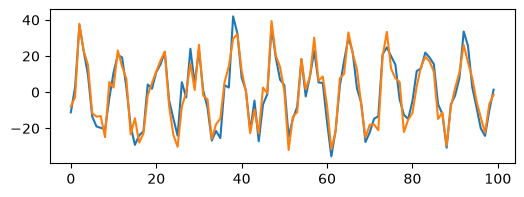

Correlation of projections: 0.951


In [11]:
plt.figure(figsize=(6,2))
plt.plot(wx.dot(X))
plt.plot(wy.dot(Y))
plt.show()
print(f'Correlation of projections: {numpy.corrcoef(wx.dot(X),wy.dot(Y))[0,1]:.3f}')